# Max-Cut on Weighted Graphs

## QAOA Circuit Construction & SWAP Bottleneck Analysis

**Team:** NexGen Minds
**Track:** Quantum Optimization — PS-O1
**Project:** Qiskit Fall Fest 2026

### Project Overview

This notebook studies the Max-Cut problem on weighted graphs using classical exhaustive search and the Quantum Approximate Optimization Algorithm (QAOA).

The classical method evaluates all possible binary assignments for each six-vertex graph to determine the exact optimal cut weight. The saved QAOA benchmark results are then compared with these classical optima using average cut weight, approximation ratio, and optimal-cut probability.

The notebook also examines circuit-transpilation metrics for the provided processor configurations, including circuit depth, total gate count, CNOT count, and explicit SWAP count.

### Objectives

1. Compute exact classical Max-Cut solutions.
2. Visualize the weighted graph instances.
3. Validate saved QAOA benchmark results against the classical optima.
4. Compare QAOA performance across the graph instances.
5. Analyze processor connectivity and transpiled circuit costs.

**Reproducibility note:** The saved QAOA results use an ideal simulator. The processor-routing metrics describe transpiled circuits, not physical hardware execution. Noise-aware results must be reported separately when implemented and validated.


In [1]:

from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# Locate the project root
ROOT = Path.cwd()

# If Jupyter was opened in another folder, locate the project root
if not (ROOT / "data" / "raw" / "maxcut_instances.json").exists():
    candidates = [
        Path(r"C:\Users\reddy\maxcut-practice"),
        ROOT.parent,
    ]
    ROOT = next(
        (p for p in candidates
         if (p / "data" / "raw" / "maxcut_instances.json").exists()),
        ROOT
    )

DATA_FILE = ROOT / "data" / "raw" / "maxcut_instances.json"

print("Project root:", ROOT)
print("Dataset exists:", DATA_FILE.exists())

assert DATA_FILE.exists(), (
    "Dataset not found. Make sure the notebook is saved in "
    r"C:\Users\reddy\maxcut-practice"
)

Project root: C:\Users\reddy\maxcut-practice
Dataset exists: True


In [2]:

# Load the actual project dataset
with DATA_FILE.open("r", encoding="utf-8-sig") as f:
    dataset = json.load(f)

print("Dataset loaded successfully!")
print("Number of graph instances:", len(dataset))

# Inspect the dataset structure
display(dataset if isinstance(dataset, list) else pd.DataFrame(
    [{"key": key, "value": str(value)[:300]}
     for key, value in dataset.items()]
))

Dataset loaded successfully!
Number of graph instances: 5


,key,value
0,dataset_name,PS-O1 Max-Cut Example Instances
1,status,team-created examples; not official fixed graphs
2,num_vertices,6
3,weight_range,"[1, 5]"
4,graphs,"[{'id': 'graph_01', 'edges': [[0, 1, 3], [0, 2..."


In [3]:

# Extract the graph instances from the dataset
graphs = dataset["graphs"]

print("Dataset name:", dataset["dataset_name"])
print("Dataset status:", dataset["status"])
print("Vertices per graph:", dataset["num_vertices"])
print("Weight range:", dataset["weight_range"])
print("Number of graph instances:", len(graphs))

# Show each graph's edges
for graph in graphs:
    print(f"\n{graph['id']}")
    print("Number of edges:", len(graph["edges"]))
    print("Edges (u, v, weight):")
    for edge in graph["edges"]:
        print(tuple(edge))

Dataset name: PS-O1 Max-Cut Example Instances
Dataset status: team-created examples; not official fixed graphs
Vertices per graph: 6
Weight range: [1, 5]
Number of graph instances: 3

graph_01
Number of edges: 10
Edges (u, v, weight):
(0, 1, 3)
(0, 2, 2)
(0, 5, 4)
(1, 2, 1)
(1, 3, 5)
(2, 3, 2)
(2, 4, 4)
(3, 4, 3)
(3, 5, 1)
(4, 5, 5)

graph_02
Number of edges: 10
Edges (u, v, weight):
(0, 1, 2)
(0, 3, 5)
(0, 4, 1)
(1, 2, 4)
(1, 4, 3)
(1, 5, 2)
(2, 3, 1)
(2, 5, 5)
(3, 4, 4)
(4, 5, 3)

graph_03
Number of edges: 10
Edges (u, v, weight):
(0, 2, 5)
(0, 3, 2)
(0, 5, 1)
(1, 2, 3)
(1, 3, 4)
(1, 4, 2)
(2, 4, 1)
(2, 5, 4)
(3, 4, 5)
(4, 5, 3)


##  Classical Max-Cut: Exact Solution

We evaluate every possible binary assignment for each six-vertex weighted graph.
 For each assignment, we calculate the total weight of edges whose endpoints belong to different partitions. The maximum cut weight is the exact classical optimum.


In [4]:

from itertools import product

def calculate_cut_weight(edges, bitstring):
    """Sum weights of edges whose endpoints are in different partitions."""
    return sum(
        weight
        for u, v, weight in edges
        if bitstring[u] != bitstring[v]
    )

classical_results = []

for graph in graphs:
    edges = graph["edges"]
    n = dataset["num_vertices"]

    candidates = []

    for bits in product([0, 1], repeat=n):
        bitstring = "".join(map(str, bits))
        cut_weight = calculate_cut_weight(edges, bits)
        candidates.append((bitstring, cut_weight))

    optimum = max(weight for _, weight in candidates)
    optimal_assignments = [
        bits for bits, weight in candidates if weight == optimum
    ]

    classical_results.append({
        "graph_id": graph["id"],
        "vertices": n,
        "edges": len(edges),
        "classical_optimum": optimum,
        "optimal_assignments": len(optimal_assignments),
        "assignments_checked": len(candidates),
        "example_optimal_bitstring": optimal_assignments[0],
    })

classical_df = pd.DataFrame(classical_results)
display(classical_df)

,graph_id,vertices,edges,classical_optimum,optimal_assignments,assignments_checked,example_optimal_bitstring
0,graph_01,6,10,26,2,64,011001
1,graph_02,6,10,27,2,64,010101
2,graph_03,6,10,24,4,64,001100


## Weighted Graph Visualization

The dataset contains three team-created weighted Max-Cut instances, each with six vertices and ten edges. Each edge has an associated weight that contributes to the cut objective when its endpoints are assigned to different partitions.

Visualizing the graph instances helps us understand their connectivity and edge weights before analyzing their classical and QAOA results.


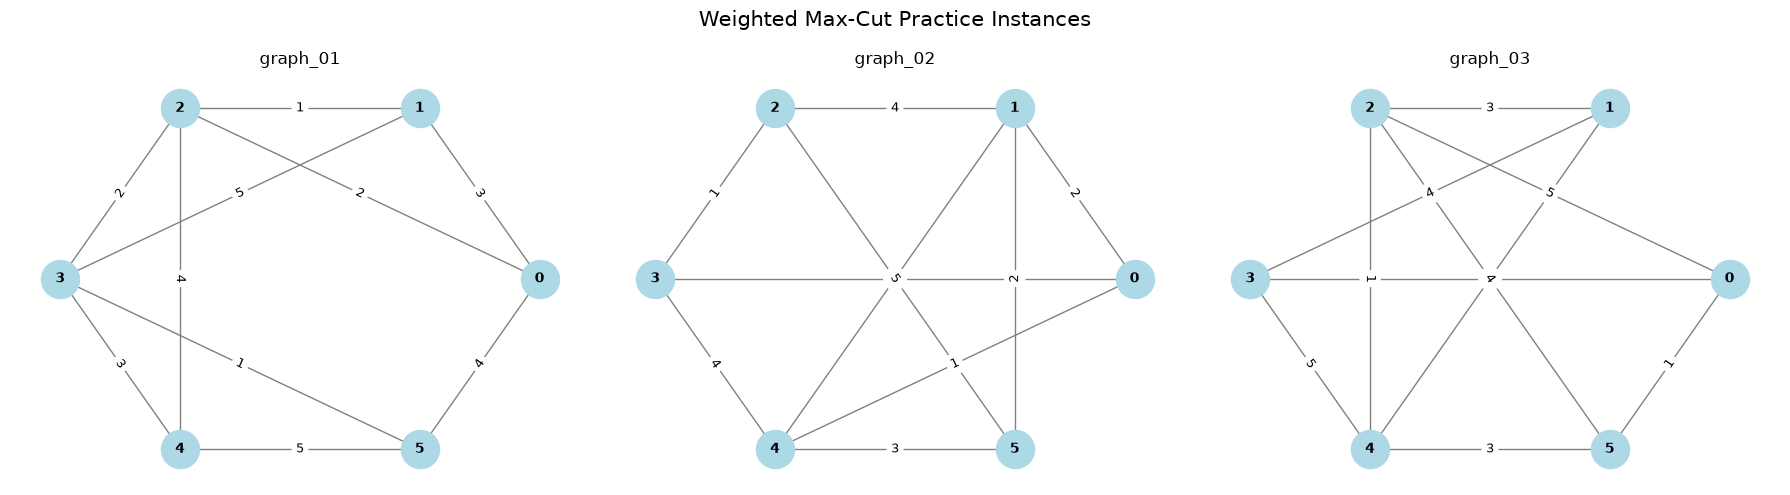

In [5]:

# Visualize each graph using its actual edges and weights
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, graph in zip(axes, graphs):
    G = nx.Graph()
    G.add_nodes_from(range(dataset["num_vertices"]))

    for u, v, weight in graph["edges"]:
        G.add_edge(u, v, weight=weight)

    pos = nx.circular_layout(G)
    edge_labels = nx.get_edge_attributes(G, "weight")

    nx.draw_networkx(
        G, pos, ax=ax,
        node_color="lightblue",
        node_size=750,
        font_size=10,
        font_weight="bold",
        edge_color="gray"
    )
    nx.draw_networkx_edge_labels(
        G, pos, edge_labels=edge_labels,
        ax=ax, font_size=9
    )

    ax.set_title(graph["id"])
    ax.axis("off")

plt.suptitle("Weighted Max-Cut Practice Instances", fontsize=15)
plt.tight_layout()
plt.show()

In [6]:

# Compare independently calculated results with the saved CSV
classical_csv = ROOT / "results" / "tables" / "classical_optima.csv"
saved_classical_df = pd.read_csv(classical_csv)

comparison = classical_df.merge(
    saved_classical_df,
    on="graph_id",
    suffixes=("_notebook", "_saved")
)

comparison["optimum_matches"] = (
    comparison["classical_optimum_notebook"]
    == comparison["classical_optimum_saved"]
)

comparison["optimal_count_matches"] = (
    comparison["optimal_assignments"]
    == comparison["optimal_assignments_count"]
)

comparison["assignments_checked_matches"] = (
    comparison["assignments_checked_notebook"]
    == comparison["assignments_checked_saved"]
)

display(comparison[[
    "graph_id",
    "classical_optimum_notebook",
    "classical_optimum_saved",
    "optimal_assignments",
    "optimal_assignments_count",
    "optimum_matches",
    "optimal_count_matches",
    "assignments_checked_matches"
]])

assert comparison["optimum_matches"].all()
assert comparison["optimal_count_matches"].all()
assert comparison["assignments_checked_matches"].all()

print("PASS: Notebook calculations match saved classical results.")

,graph_id,classical_optimum_notebook,classical_optimum_saved,optimal_assignments,optimal_assignments_count,optimum_matches,optimal_count_matches,assignments_checked_matches
0,graph_01,26,26,2,2,True,True,True
1,graph_02,27,27,2,2,True,True,True
2,graph_03,24,24,4,4,True,True,True


PASS: Notebook calculations match saved classical results.


## QAOA Benchmark Results

The Quantum Approximate Optimization Algorithm (QAOA) is a hybrid quantum-classical approach for approximate combinatorial optimization. In this experiment, saved QAOA benchmark results are compared against the exact classical Max-Cut optima.

We examine the average cut weight, average approximation ratio, best sampled cut, and probability of sampling an optimal cut.

**Important:** The reported parameters were selected using a coarse grid search. These results represent the tested parameter combinations and do not establish a globally optimal QAOA configuration.


In [7]:

# Load the saved QAOA parameter-search results
qaoa_csv = ROOT / "results" / "tables" / "qaoa_optimization.csv"
qaoa_df = pd.read_csv(qaoa_csv)

print("Saved QAOA parameter-search results")
display(qaoa_df)

# Check that each graph's best sampled cut reaches its classical optimum
qaoa_check = qaoa_df.merge(
    classical_df[["graph_id", "classical_optimum"]],
    on="graph_id",
    suffixes=("_qaoa", "_classical")
)

qaoa_check["best_cut_matches_optimum"] = (
    qaoa_check["best_sampled_cut"]
    == qaoa_check["classical_optimum_classical"]
)

display(qaoa_check[[
    "graph_id",
    "gamma",
    "beta",
    "shots",
    "classical_optimum_classical",
    "best_sampled_cut",
    "average_cut",
    "average_approximation_ratio",
    "optimal_cut_probability",
    "best_cut_matches_optimum"
]])

assert qaoa_check["best_cut_matches_optimum"].all()
print("PASS: Every graph sampled an optimal cut in the saved QAOA results.")

Saved QAOA parameter-search results


,graph_id,gamma,beta,shots,classical_optimum,best_sampled_cut,average_cut,average_approximation_ratio,best_sampled_approximation_ratio,optimal_cut_probability
0,graph_01,0.1,0.3,4096,26,26,19.3484,0.7442,1.0,0.131592
1,graph_02,0.1,0.3,4096,27,27,19.1550,0.7094,1.0,0.133789
2,graph_03,0.1,0.3,4096,24,24,19.2749,0.8031,1.0,0.194092


,graph_id,gamma,beta,shots,classical_optimum_classical,best_sampled_cut,average_cut,average_approximation_ratio,optimal_cut_probability,best_cut_matches_optimum
0,graph_01,0.1,0.3,4096,26,26,19.3484,0.7442,0.131592,True
1,graph_02,0.1,0.3,4096,27,27,19.1550,0.7094,0.133789,True
2,graph_03,0.1,0.3,4096,24,24,19.2749,0.8031,0.194092,True


PASS: Every graph sampled an optimal cut in the saved QAOA results.


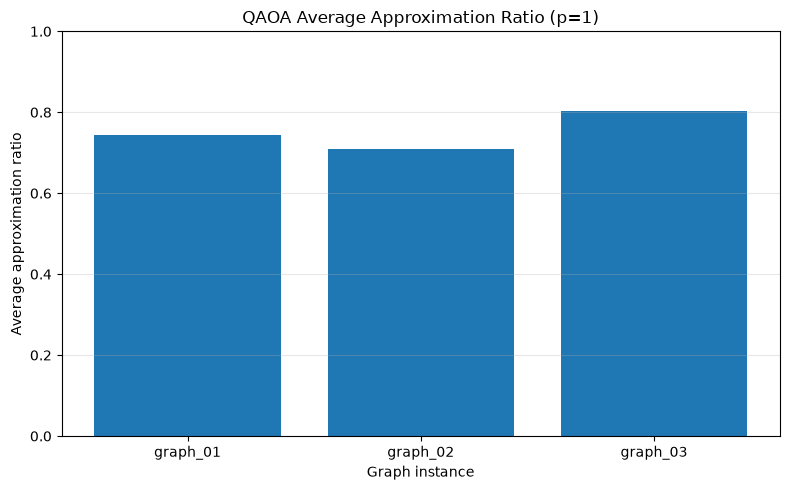

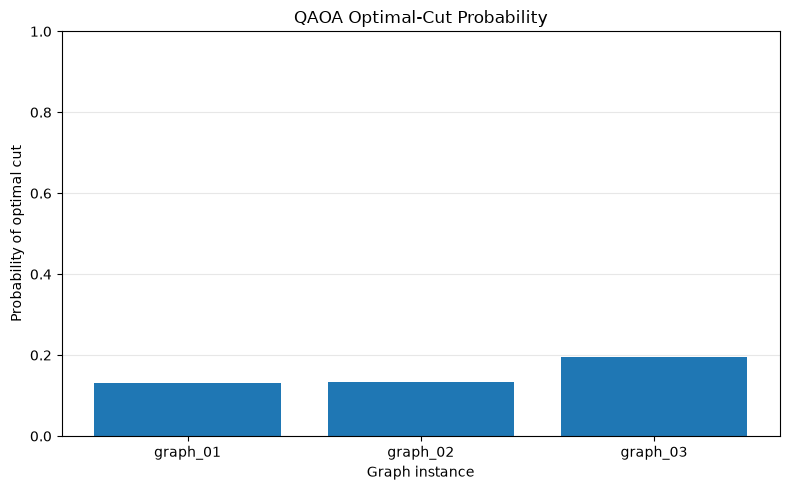

In [8]:

# Plot average approximation ratio for each graph
plt.figure(figsize=(8, 5))

plt.bar(
    qaoa_df["graph_id"],
    qaoa_df["average_approximation_ratio"]
)

plt.ylim(0, 1)
plt.ylabel("Average approximation ratio")
plt.xlabel("Graph instance")
plt.title("QAOA Average Approximation Ratio (p=1)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Plot probability of sampling an optimal cut
plt.figure(figsize=(8, 5))

plt.bar(
    qaoa_df["graph_id"],
    qaoa_df["optimal_cut_probability"]
)

plt.ylim(0, 1)
plt.ylabel("Probability of optimal cut")
plt.xlabel("Graph instance")
plt.title("QAOA Optimal-Cut Probability")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Processor Connectivity and Routing Analysis

This section compares the feasibility and transpiled circuit costs for the supplied processor configurations.

Processor A has five physical qubits, so it cannot directly accommodate the six-qubit problem mapping used in this benchmark. Processor B has nine physical qubits and supports the tested six-qubit mapping.

We compare circuit depth, total gate count, CNOT count, and explicit SWAP count to understand the compiled circuit costs.

**Interpretation note:** These are transpilation results, not measurements from real quantum hardware. A reported SWAP count of zero does not, by itself, prove that routing overhead is absent.


In [9]:

# Load Processor A/B routing benchmark
routing_csv = ROOT / "results" / "tables" / "processor_routing_comparison.csv"
routing_df = pd.read_csv(routing_csv)

print("Processor routing benchmark")
display(routing_df)

# Summarize feasible Processor B circuit metrics
processor_b = routing_df[
    (routing_df["processor"] == "Processor B")
    & (routing_df["mapping_feasible"] == True)
].copy()

display(processor_b[[
    "graph_id",
    "depth",
    "total_gates",
    "cx_count",
    "explicit_swap_count",
    "status"
]])

print("Note: these are ideal transpilation metrics, not hardware measurements.")

Processor routing benchmark


,graph_id,processor,logical_qubits_required,physical_qubits_available,coupling_edges,gamma,beta,basis_gates,mapping_feasible,depth,total_gates,cx_count,explicit_swap_count,status
0,graph_01,Processor A,6,5,4,0.1,0.3,"rz,sx,x,cx",False,NaN,NaN,NaN,NaN,infeasible: insufficient physical qubits for d...
1,graph_01,Processor B,6,9,8,0.1,0.3,"rz,sx,x,cx",True,123.0,218.0,41.0,0.0,ideal transpilation only; not hardware execution
2,graph_02,Processor A,6,5,4,0.1,0.3,"rz,sx,x,cx",False,NaN,NaN,NaN,NaN,infeasible: insufficient physical qubits for d...
3,graph_02,Processor B,6,9,8,0.1,0.3,"rz,sx,x,cx",True,124.0,213.0,38.0,0.0,ideal transpilation only; not hardware execution
4,graph_03,Processor A,6,5,4,0.1,0.3,"rz,sx,x,cx",False,NaN,NaN,NaN,NaN,infeasible: insufficient physical qubits for d...
5,graph_03,Processor B,6,9,8,0.1,0.3,"rz,sx,x,cx",True,139.0,270.0,47.0,0.0,ideal transpilation only; not hardware execution


,graph_id,depth,total_gates,cx_count,explicit_swap_count,status
1,graph_01,123.0,218.0,41.0,0.0,ideal transpilation only; not hardware execution
3,graph_02,124.0,213.0,38.0,0.0,ideal transpilation only; not hardware execution
5,graph_03,139.0,270.0,47.0,0.0,ideal transpilation only; not hardware execution


Note: these are ideal transpilation metrics, not hardware measurements.


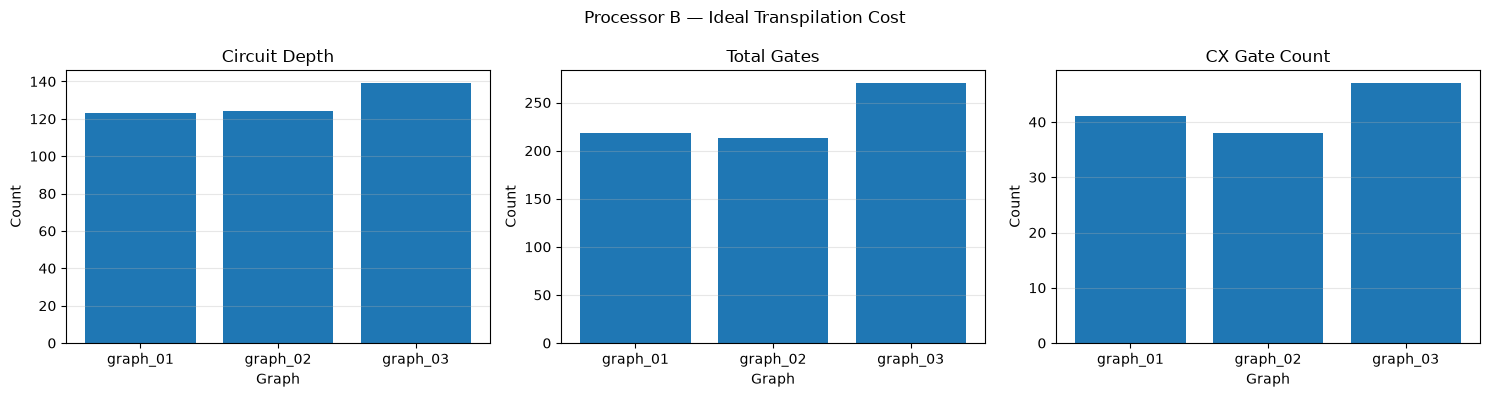

In [10]:

# Compare Processor B circuit cost across the three graphs
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = [
    ("depth", "Circuit Depth"),
    ("total_gates", "Total Gates"),
    ("cx_count", "CX Gate Count"),
]

for ax, (column, title) in zip(axes, metrics):
    ax.bar(processor_b["graph_id"], processor_b[column])
    ax.set_title(title)
    ax.set_xlabel("Graph")
    ax.set_ylabel("Count")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Processor B — Ideal Transpilation Cost")
plt.tight_layout()
plt.show()

## Results and Conclusion

### Key Findings

* **Classical benchmark:** Exhaustive search evaluates all \(2^6 = 64\) binary assignments for each six-vertex graph and identifies the exact optimum.
* **QAOA performance:** The saved QAOA results sampled an optimal cut for all three graph instances. This demonstrates that optimal solutions appeared among the sampled outcomes, not that every measurement was optimal.
* **Parameter search:** The tested grid covered 32 combinations per graph. A wider search and multiple independent runs could help assess parameter sensitivity.
* **Processor feasibility:** Processor A's five-qubit configuration is insufficient for the tested direct six-qubit mapping, while Processor B supports the tested mapping.
* **Circuit cost:** Transpilation metrics provide a baseline for comparing compiled circuits, but they are not hardware performance measurements.

### Limitations and Future Work

1. Implement and validate the challenge-specified noise model.
2. Complete the required Processor D design and document its connectivity.
3. Run repeated QAOA experiments with different seeds and parameter initializations.
4. Compare ideal and noise-aware results using consistent metrics.
5. Document the methodology, configuration, results, and reproducibility steps in the final report.

### Final Conclusion

This project establishes a reproducible starting point for studying weighted Max-Cut with classical exhaustive search, QAOA simulation, and processor-aware circuit transpilation. The next stage is to validate noise-aware behavior and complete the remaining architecture and reporting requirements before submission.
